[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LRCole3/pre-training-pathway/blob/main/01_ngrams_and_embeddings.ipynb)

# 01 · Counting and Embeddings: What a Language Model Is, and Where a Fixed Window Fails

## Overview

*Pre-training* means learning general knowledge from raw data before any specific task is given. This series
follows how that idea developed, for **language** (notebooks 01–05), for **images** (06–09), and for both at
once (10). Each method appears *because the previous one fails at something measurable*.

| # | Notebook | Idea | What it fixes | What it leaves open |
|---|---|---|---|---|
| **01** | **Counting and embeddings** | **Count n-grams; learn word vectors** | **A first language model; similar words get similar vectors** | **Fixed window; one vector per word** |
| 02 | RNNs, attention, ELMo | Carry a state; look back with attention; reuse the pretrained network | Context beyond a window; contextual features | Memory fades with distance; no parallel training |
| 03 | The transformer | Attention only, then today's block (RoPE, RMSNorm, SwiGLU, GQA, MoE) | Direct access to any earlier token; parallel training | Needs an objective and a transfer recipe |
| 04 | Objectives and transfer | Causal, masked and span-corruption pretraining | Representations that transfer with few labels | No objective wins everything; optimisation untested |
| 05 | Making it scale | Tokenisers, the optimiser recipe, scaling laws | A recipe that keeps improving with size | Discrete tokens only |
| 06 | VAE, GAN, pixel models | Generative models for images before diffusion | Sampling images at all | Blur, mode collapse, slow sampling |
| 07 | Diffusion design space | Denoise step by step; schedule, target, weighting | Quality and coverage together | Pixel space, MLP backbone, no text |
| 08 | Encoders, CLIP, latent diffusion | Pretrain the parts: vision encoder, text-image model, autoencoder | Conditioning and compression | The backbone still does not scale |
| 09 | Diffusion transformers | Patch tokens, flow matching, training accelerators | A scalable denoiser | Base models still need post-training |
| 10 | Capstone | One backbone, three objectives, two modalities | A unified view of pretraining | The post-training series starts here |

This first notebook covers the starting point: language models that **count** ([Shannon, 1951](https://doi.org/10.1002/j.1538-7305.1951.tb01366.x), [Chen & Goodman, 1996](https://arxiv.org/abs/cmp-lg/9606011)),
the first neural language model (Bengio and colleagues, 2003), and **word embeddings** ([Mikolov et al., 2013](https://arxiv.org/abs/1301.3781)),
which were the first widely reused pretrained component in language processing.

Everything is trained on a small synthetic language whose generator we wrote ourselves. That gives us three
measurements real corpora cannot: the **exact best achievable loss**, a **recall test** at any distance, and a
**hidden label** per document.

## Learning objectives

1. State what a language model is and compute the lowest loss any model could reach on a corpus with a known generator.
2. Build n-gram models, explain why they need smoothing, and measure how sparsity grows with context length.
3. Train a fixed-window neural language model and skip-gram embeddings, and read an embedding space.
4. Measure the two limits that motivate notebook 02: a **fixed window** and **one vector per word**.

**Runtime:** about 3 minutes on a laptop CPU.

In [1]:
# Setup. Locally this only adds the repo to the path. In Colab it first clones the repository (untested path).
import os, sys
if "google.colab" in sys.modules and not os.path.exists("prelib"):
    os.system("git clone -q https://github.com/LRCole3/pre-training-pathway.git"); os.chdir("pre-training-pathway")
sys.path.insert(0, ".")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from prelib import world as W, classic as C, viz, metrics, set_seed
viz.style()
torch.set_num_threads(min(8, torch.get_num_threads()))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
train, test = W.corpus("train"), W.corpus("test")
print(f"{train['tokens'].shape[0]:,} training documents of {W.DOC_LEN} tokens; vocabulary of {W.VOCAB} tokens")

20,000 training documents of 64 tokens; vocabulary of 81 tokens


## 1. The world: a language with a known generator

Each document is 64 tokens long and mixes three ingredients.

* **Filler words** such as `noza` or `tovur`. Every word belongs to one of six classes, visible in its suffix
  (`-a`, `-ek`, `-is`, `-om`, `-ur`, `-ly`), a little like parts of speech.
* A hidden **style** (3 options) that sets which class tends to follow which, and a hidden **topic** (4 options)
  that sets which words of a class are preferred. Neither is ever written in the document.
* **Bindings and queries.** `set D 8` binds key `D` to value `8`. Later, `ask D` must be followed by `8`. The answer
  is certain, but only for a reader who remembers the binding.

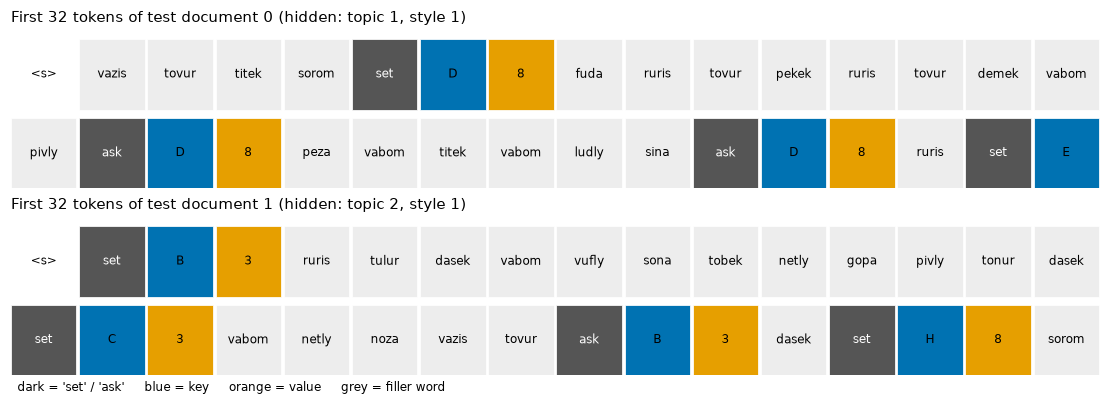

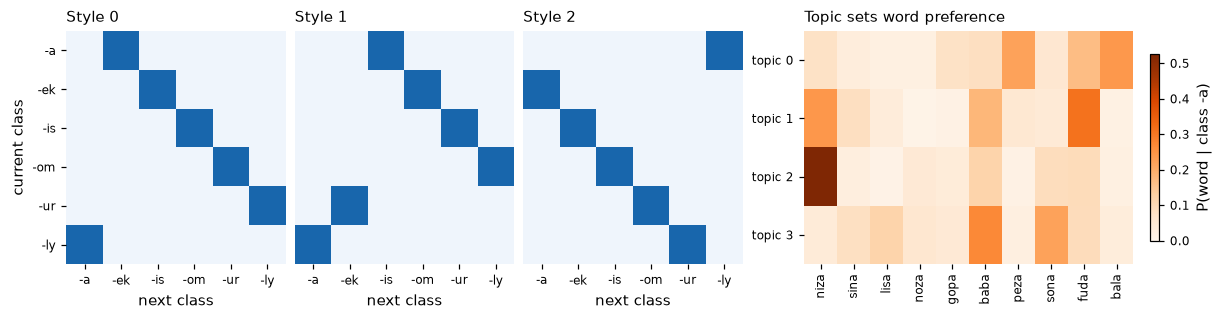

In [2]:
fig, axes = plt.subplots(2, 1, figsize=(10, 3.4))
for ax, i in zip(axes, [0, 1]):
    toks = test["tokens"][i][:32]
    viz.token_strip(ax, [W.WORDS[t] for t in toks], colors=viz.doc_colors(toks), wrap=16, fontsize=8)
    ax.set_title(f"First 32 tokens of test document {i} (hidden: topic {test['topic'][i]}, style {test['style'][i]})")
fig.text(0.01, -0.03, "dark = 'set' / 'ask'     blue = key     orange = value     grey = filler word", fontsize=8)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(11, 2.8), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.5]))
cls = [f"-{s}" for s in W.SUFFIX]
for s in range(3):
    viz.heat(axes[s], W.T_STYLE[s], xlabels=cls, ylabels=cls if s == 0 else None, cmap="Blues", vmin=0, vmax=1)
    axes[s].set_title(f"Style {s}"); axes[s].set_xlabel("next class")
    if s: axes[s].set_yticks([])
axes[0].set_ylabel("current class")
viz.heat(axes[3], W.E_TOPIC[:, 0], xlabels=[W.WORDS[W.FILL0 + w] for w in range(W.N_WORD)], ylabels=[f"topic {z}" for z in range(4)],
         cmap="Oranges", vmin=0, cbar="P(word | class -a)")
axes[3].set_title("Topic sets word preference")
plt.show()

The three left panels are the styles: each sends a class to its own favourite next class 79% of the time. All three
use every class equally often overall, so **counting words tells you nothing about the style; only word order does**.
The right panel shows topics: within one class, each topic prefers different words.

## 2. The floor: the lowest loss any model can reach

A language model assigns a probability to the next token given the tokens so far. We score it by the average
**cross-entropy**, in nats per token:
$$\mathcal{L} = -\frac{1}{T}\sum_{t} \log p_\theta(x_t \mid x_{<t}).$$

Shannon showed that this quantity has a lower bound, the entropy of the source ([Shannon, 1948](https://doi.org/10.1002/j.1538-7305.1948.tb01338.x)), and estimated it for
English by having people guess the next letter ([Shannon, 1951](https://doi.org/10.1002/j.1538-7305.1951.tb01366.x)). For real text the bound is unknown. Here we can
compute it. The best possible predictor knows the rules of the generator but not the document's topic and style; it
infers them from the tokens it has read, using Bayes' rule. `world.py` runs that predictor on the test set.

uniform guessing: 4.394 nats/token   |   oracle floor: 2.470   |   if topic and style were given: 2.431


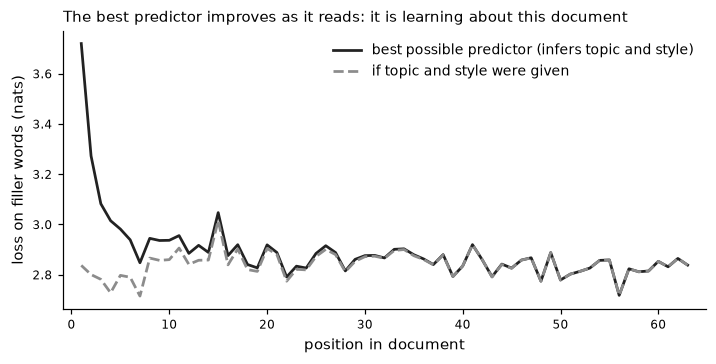

In [3]:
floor = W.floor()
print(f"uniform guessing: {np.log(W.VOCAB):.3f} nats/token   |   oracle floor: {floor:.3f}   |   "
      f"if topic and style were given: {-test['logp_latent'][:, 1:].mean():.3f}")
fill = test["kind"] == W.K_FILL
pos = np.arange(1, W.DOC_LEN)
bayes = np.array([-test["logp_bayes"][:, t][fill[:, t]].mean() for t in pos])
known = np.array([-test["logp_latent"][:, t][fill[:, t]].mean() for t in pos])
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.plot(pos, bayes, color=viz.BLACK, label="best possible predictor (infers topic and style)")
ax.plot(pos, known, color=viz.GREY, ls="--", label="if topic and style were given")
ax.set_xlabel("position in document"); ax.set_ylabel("loss on filler words (nats)")
ax.set_title("The best predictor improves as it reads: it is learning about this document"); ax.legend()
plt.show()

Two things to take from this figure. First, **no model can beat the solid line on average**, so from here on we
report each model's **gap to the floor** rather than its raw loss. Second, even the ideal predictor starts each
document uncertain and improves as it reads. It is using the context to work out the hidden topic and style. A model
that looks at only the last few tokens cannot do that.

## 3. Counting: n-gram models

The simplest language model looks at the previous $n-1$ tokens and counts what followed them in the training data:
$$p(x_t \mid x_{t-n+1}, \dots, x_{t-1}) = \frac{\text{count}(x_{t-n+1} \dots x_{t-1}\, x_t)}{\text{count}(x_{t-n+1} \dots x_{t-1})}.$$

The animation shows what a 4-gram model can see as it moves through a document: three tokens of context (outlined)
and the token it must predict (red outline). Watch what happens to the binding `set A 7`.

In [4]:
toks, target = W.recall_set(12)
doc = toks[0][:target + 1]
words = [W.WORDS[t] for t in doc]
fig, ax = plt.subplots(figsize=(10, 1.5))
def frame(t):
    ax.clear()
    edge = [None] * len(doc)
    for j in range(max(0, t - 3), t):
        edge[j] = viz.BLACK
    edge[t] = viz.VERMILION
    viz.token_strip(ax, words, colors=viz.doc_colors(doc), wrap=len(doc), fontsize=8, edge=edge)
    seen = "inside" if t - 3 <= 3 else f"{t - 3 - 3} tokens behind"
    ax.set_title(f"4-gram model predicting token {t}: context = the 3 outlined tokens; the bound value is {seen} the window")
gif = viz.save_gif(fig, frame, range(4, len(doc)), "nb01_sliding_window.gif", fps=2)

saved figures/nb01_sliding_window.gif  (12 frames drawn, 44 kB)


![A 4-gram context window sliding along a document; the binding leaves the window long before the query](figures/nb01_sliding_window.gif)

By the time the model reaches `ask A`, the binding is far outside its window. Now fit models for $n = 1 \dots 6$.
With raw counts, an unseen combination would get probability zero, so we use the simplest fix, **add-k smoothing**:
add a small constant $k$ to every count.

,gap to floor,contexts never seen in training
n,,
1,1.714,0.000
2,0.814,0.000
3,0.708,0.000
4,1.023,0.042
5,1.554,0.318
6,1.761,0.692


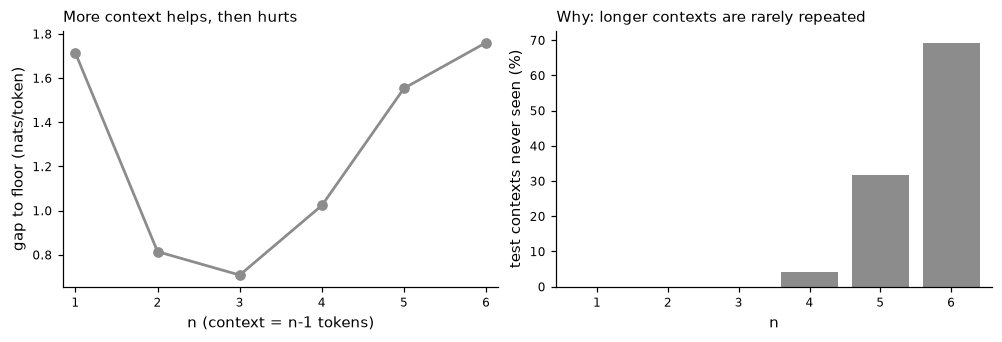

In [5]:
results, models = {}, {}
for smoothing in ["add-k", "kn"]:
    for n in range(1, 7):
        models[(smoothing, n)] = C.NGram(n, smoothing).fit(train["tokens"])
        results[(smoothing, n)] = W.evaluate_lm(models[(smoothing, n)].logprobs)
unseen = [models[("add-k", n)].unseen_fraction(test["tokens"]) for n in range(1, 7)]
addk = pd.DataFrame({"n": range(1, 7), "gap to floor": [results[("add-k", n)]["gap"] for n in range(1, 7)],
                     "contexts never seen in training": unseen}).set_index("n")
display(addk.round(3))
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(addk.index, addk["gap to floor"], "o-", color=viz.GREY)
axes[0].set_xlabel("n (context = n-1 tokens)"); axes[0].set_ylabel("gap to floor (nats/token)")
axes[0].set_title("More context helps, then hurts")
axes[1].bar(addk.index, 100 * addk["contexts never seen in training"], color=viz.GREY)
axes[1].set_xlabel("n"); axes[1].set_ylabel("test contexts never seen (%)"); axes[1].set_title("Why: longer contexts are rarely repeated")
plt.show()

**Reading the result.** The first token of context cuts the gap by more than half, and the second helps a little
more. Beyond $n = 3$ the gap **grows** again.
The right panel shows why: the number of possible contexts multiplies by 81 with every extra token, while the
training set stays the same size. For $n = 6$ most test contexts were never seen in training, and the model falls
back to guessing. This is the **sparsity** problem, and it is why counting cannot simply be given a longer memory.

## 4. Design choice: how to smooth

Add-k treats every unseen word as equally likely. **Kneser–Ney smoothing**, the best method in the careful comparison
of [Chen & Goodman, 1996](https://arxiv.org/abs/cmp-lg/9606011), does two smarter things. It *backs off*: when a long context is rare, it leans on the shorter
context. And for those shorter contexts it asks not "how often did this word occur?" but "in how many different
contexts did it occur?":
$$p_{\text{KN}}(w \mid c) = \frac{\max(\text{count}(c, w) - D,\, 0)}{\text{count}(c)} + \lambda(c)\; p_{\text{KN}}(w \mid c'),$$
where $c'$ is the context with its oldest token dropped, $D$ is a fixed discount, and $\lambda(c)$ hands the
discounted probability mass to the shorter-context model.

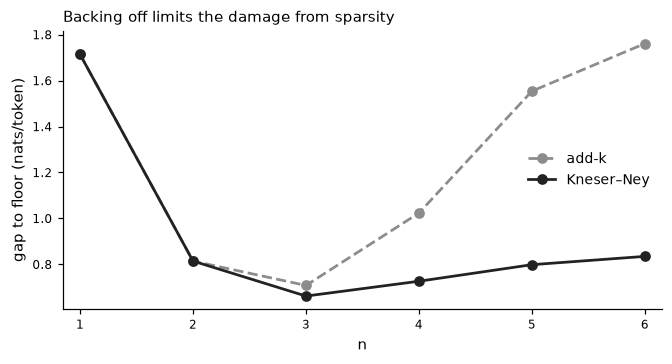

best n-gram: Kneser-Ney with n = 3, gap 0.662 nats/token


In [6]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for smoothing, label, ls in [("add-k", "add-k", "--"), ("kn", "Kneser\u2013Ney", "-")]:
    ax.plot(range(1, 7), [results[(smoothing, n)]["gap"] for n in range(1, 7)], "o", ls=ls, color=viz.GREY if smoothing == "add-k" else viz.BLACK, label=label)
ax.set_xlabel("n"); ax.set_ylabel("gap to floor (nats/token)"); ax.set_title("Backing off limits the damage from sparsity"); ax.legend()
plt.show()
best_n = min(range(1, 7), key=lambda n: results[("kn", n)]["gap"])
print(f"best n-gram: Kneser-Ney with n = {best_n}, gap {results[('kn', best_n)]['gap']:.3f} nats/token")

Kneser–Ney removes most of the damage at large $n$, but it does not turn longer contexts into a gain here: the best
model still uses only two tokens of context. Smoothing manages sparsity; it does not remove it.

### Try it: order and smoothing

The explorer refits a model for the chosen settings and shows a document sampled from it. With $n = 1$ the sample is
word salad. With larger $n$ the statements (`set`, key, value) come out well formed, but look at whether an `ask` is
followed by the right value.

Static preview at the default settings {'n': 3, 'smoothing': 'kn', 'k': 0.1}. Run the notebook to get the controls.


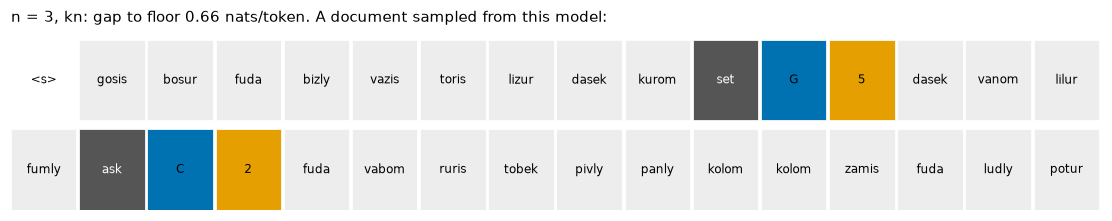

In [7]:
def ngram_explorer(n=3, smoothing="kn", k=0.1):
    m = C.NGram(n, smoothing, k=k).fit(train["tokens"])
    gap = W.evaluate_lm(m.logprobs, distances=(8,))["gap"]
    sample = m.sample(32, seed=1)
    fig, ax = plt.subplots(figsize=(10, 1.9))
    viz.token_strip(ax, [W.WORDS[t] for t in sample], colors=viz.doc_colors(sample), wrap=16, fontsize=8)
    ax.set_title(f"n = {n}, {smoothing}" + (f" (k = {k})" if smoothing == "add-k" else "") + f": gap to floor {gap:.2f} nats/token. A document sampled from this model:")
    plt.show()
viz.explore(ngram_explorer, n=(1, 6, 1, 3), smoothing=["kn", "add-k"], k=(0.01, 1.0, 0.01, 0.1))

## 5. The recall cliff

The recall test places one binding at the start of a document and its query a chosen number of tokens later, then
asks whether the model's top guess for the value is right. Guessing among the eight values gives 12.5%.

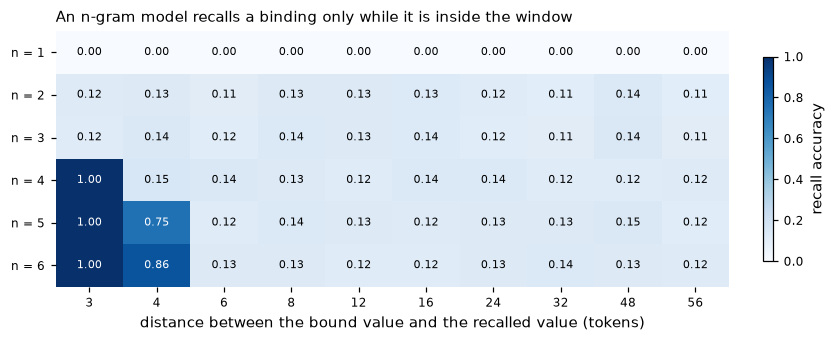

In [8]:
dists = list(W.RECALL_DISTANCES)
R = np.array([[results[("kn", n)]["recall"][d] for d in dists] for n in range(1, 7)])
fig, ax = plt.subplots(figsize=(7.5, 3))
viz.heat(ax, R, xlabels=dists, ylabels=[f"n = {n}" for n in range(1, 7)], annotate=True, cmap="Blues", vmin=0, vmax=1, cbar="recall accuracy")
ax.set_xlabel("distance between the bound value and the recalled value (tokens)")
ax.set_title("An n-gram model recalls a binding only while it is inside the window")
plt.show()

**Reading the result.** Recall is perfect at distance 3 once the context reaches back that far ($n \ge 4$), partial
at distance 4 ($n = 5$ and $6$), and at chance, about 12%, everywhere beyond. Each extra token of context moves the
cliff by at most one token, and section 3 showed that the price is a worse model everywhere else. Counting cannot be
the way to longer memory.

## 6. A neural language model with a fixed window

The first neural language model (Bengio and colleagues, 2003, *Journal of Machine Learning Research*) kept the fixed
window but replaced the count table with a network. Each of the previous $w$ tokens is mapped to a learned vector, an
**embedding**; the vectors are concatenated and passed through a small network that outputs a probability for every
word. Similar words get similar vectors, so what the model learns about one context transfers to similar contexts it
has never seen. That directly attacks sparsity.

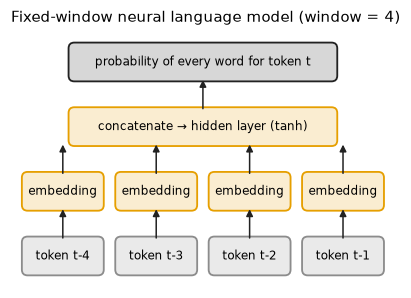

window  2: gap 0.630 nats/token  (9s)
window  4: gap 0.483 nats/token  (9s)
window  8: gap 0.341 nats/token  (12s)
window 16: gap 0.269 nats/token  (18s)


In [9]:
fig, ax = plt.subplots(figsize=(9, 2.6))
boxes = [(i * 1.3, 0, 1.1, 0.5, f"token t-{4 - i}", viz.GREY) for i in range(4)]
boxes += [(i * 1.3, 0.9, 1.1, 0.5, "embedding", viz.ORANGE) for i in range(4)]
boxes += [(0.65, 1.8, 3.7, 0.5, "concatenate \u2192 hidden layer (tanh)", viz.ORANGE), (0.65, 2.7, 3.7, 0.5, "probability of every word for token t", viz.BLACK)]
arrows = [(i * 1.3 + 0.55, 0.5, i * 1.3 + 0.55, 0.9) for i in range(4)] + [(i * 1.3 + 0.55, 1.4, i * 1.3 + 0.55, 1.8) for i in range(4)] + [(2.5, 2.3, 2.5, 2.7)]
viz.diagram(ax, boxes, arrows, fontsize=8); ax.set_title("Fixed-window neural language model (window = 4)")
plt.show()

mlp, mlp_res, mlp_secs = {}, {}, {}
for window in [2, 4, 8, 16]:
    set_seed(0)
    mlp[window] = C.WindowMLP(window=window)
    t0 = time.time()
    C.train_lm(mlp[window], train["tokens"], steps=1500, batch=64, lr=2e-3)
    mlp_secs[window] = time.time() - t0
    mlp_res[window] = W.evaluate_lm(mlp[window].logprobs)
    print(f"window {window:2d}: gap {mlp_res[window]['gap']:.3f} nats/token  ({mlp_secs[window]:.0f}s)")

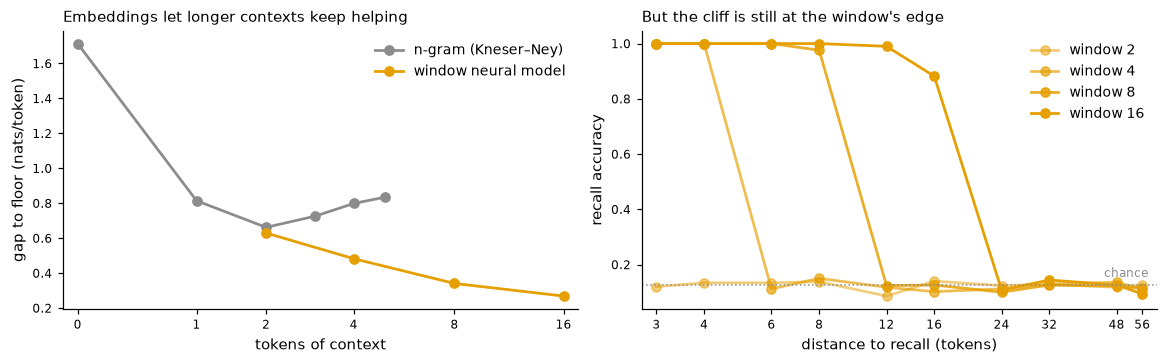

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.2))
axes[0].plot(range(1, 7), [results[("kn", n)]["gap"] for n in range(1, 7)], "o-", color=viz.FAMILY["n-gram"], label="n-gram (Kneser\u2013Ney)")
axes[0].plot([w + 1 for w in mlp], [mlp_res[w]["gap"] for w in mlp], "o-", color=viz.FAMILY["window MLP"], label="window neural model")
axes[0].set_xscale("log", base=2); axes[0].set_xticks([1, 2, 3, 5, 9, 17]); axes[0].set_xticklabels([0, 1, 2, 4, 8, 16])
axes[0].set_xlabel("tokens of context"); axes[0].set_ylabel("gap to floor (nats/token)"); axes[0].legend()
axes[0].set_title("Embeddings let longer contexts keep helping")
for w in mlp:
    axes[1].plot(dists, [mlp_res[w]["recall"][d] for d in dists], "o-", color=viz.ORANGE, alpha=0.35 + 0.65 * (np.log2(w) / 4), label=f"window {w}")
axes[1].axhline(1 / W.N_VAL, color=viz.GREY, ls=":", lw=1); axes[1].text(58, 1 / W.N_VAL + 0.03, "chance", ha="right", fontsize=8, color=viz.GREY)
axes[1].set_xscale("log", base=2); axes[1].set_xticks(dists); axes[1].set_xticklabels(dists)
axes[1].set_xlabel("distance to recall (tokens)"); axes[1].set_ylabel("recall accuracy"); axes[1].legend()
axes[1].set_title("But the cliff is still at the window's edge")
plt.show()

**Reading the result.** The neural model keeps improving as its window grows, where the count model got worse. With
embeddings, a longer context is no longer a rarer context. Recall, though, shows the same cliff as before, now at
the edge of the window. A window of 16 tokens covers a quarter of a document; covering a long document this way would
need an input layer that grows with the document. The window is the limit, and notebook 02 removes it.

## 7. Word embeddings on their own: skip-gram

The embeddings inside the window model turned out to be valuable by themselves. **word2vec** ([Mikolov et al., 2013](https://arxiv.org/abs/1301.3781)) trains
*only* embeddings, with a deliberately trivial task so that it can run over billions of words: given a word, predict
the words within a few positions of it (**skip-gram**). Each word $w$ gets an input vector $v_w$ and an output vector
$u_w$, and
$$p(o \mid w) = \frac{\exp(u_o^\top v_w)}{\sum_{o'} \exp(u_{o'}^\top v_w)}.$$
Words that appear in similar contexts are pushed toward similar vectors. The trained vectors were then reused as the
first layer of other models, which makes them the first widely used *pretrained* component for language.
GloVe ([Pennington et al., 2014](https://doi.org/10.3115/v1/D14-1162)) reaches similar vectors by factorising a table of co-occurrence counts.

The animation follows the vectors of the 60 filler words during training, projected to two dimensions and coloured by
word class.

saved figures/nb01_embeddings_forming.gif  (30 frames drawn, 172 kB)


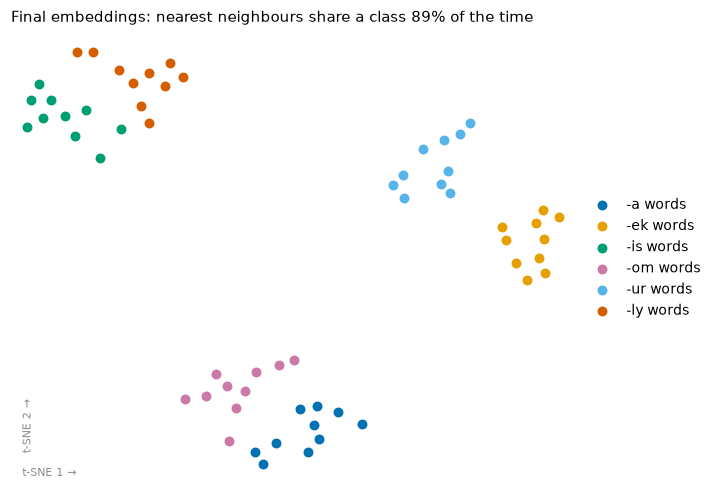

In [11]:
E, snaps, secs_neg = C.train_skipgram(train["tokens"], method="negative", steps=1500, snapshot_every=50)
fill_ids = np.arange(W.FILL0, W.VOCAB)
cls_of = W.WORD_CLASS[fill_ids]
colors = [viz.class_colors()[c] for c in cls_of]
Ef = E[fill_ids] - E[fill_ids].mean(0)
basis = np.linalg.svd(Ef, full_matrices=False)[2][:2].T                    # project every frame onto the final axes
lim = np.abs(Ef @ basis).max() * 1.15
fig, ax = plt.subplots(figsize=(4.6, 4.2))
def frame(i):
    ax.clear()
    P = (snaps[i][fill_ids] - snaps[i][fill_ids].mean(0)) @ basis
    ax.scatter(P[:, 0], P[:, 1], c=colors, s=28)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); viz.embedding_axes(ax)
    ax.set_title(f"Skip-gram embeddings after {i * 50} training steps")
viz.save_gif(fig, frame, range(len(snaps)), "nb01_embeddings_forming.gif", fps=6)

from sklearn.manifold import TSNE
P = TSNE(n_components=2, perplexity=10, init="pca", random_state=0).fit_transform(Ef)      # a projection that keeps neighbours together
fig, ax = plt.subplots(figsize=(6.4, 4.4))
for c in range(W.N_CLASS):
    m = cls_of == c
    ax.scatter(P[m, 0], P[m, 1], color=viz.class_colors()[c], s=30, label=f"-{W.SUFFIX[c]} words")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
viz.embedding_axes(ax, ("t-SNE 1", "t-SNE 2")); ax.set_title(f"Final embeddings: nearest neighbours share a class {C.class_purity(E):.0%} of the time")
plt.show()

![Skip-gram embeddings separating into word classes during training](figures/nb01_embeddings_forming.gif)

Nobody told the model about word classes. The classes appear because words of one class occur in the same kinds of
context, which is the only signal skip-gram uses. The animation uses a fixed linear projection, in which pairs of
classes share a region. The static figure uses t-SNE, a projection that keeps neighbours together, and shows the
classes as the full 24-dimensional space arranges them.

### Try it: nearest neighbours

Static preview at the default settings {'word': 'niza'}. Run the notebook to get the controls.


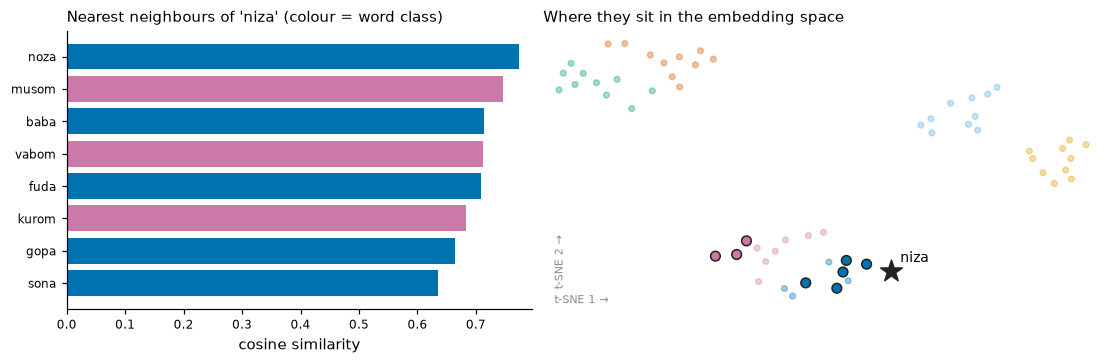

In [12]:
def neighbour_explorer(word="noza"):
    wid = W.WORDS.index(word)
    nb = C.neighbours(E, wid, 8, fill_ids)
    sims = [float(E[i] @ E[wid] / np.linalg.norm(E[i]) / np.linalg.norm(E[wid])) for i in nb]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw=dict(width_ratios=[1, 1.2]))
    axes[0].barh([W.WORDS[i] for i in nb][::-1], sims[::-1], color=[viz.class_colors()[W.WORD_CLASS[i]] for i in nb][::-1])
    axes[0].set_xlabel("cosine similarity"); axes[0].set_title(f"Nearest neighbours of '{word}' (colour = word class)")
    axes[1].scatter(P[:, 0], P[:, 1], c=colors, s=14, alpha=0.35)
    sel = [list(fill_ids).index(i) for i in nb]
    axes[1].scatter(P[sel, 0], P[sel, 1], c=[colors[i] for i in sel], s=40, edgecolor=viz.BLACK)
    q = list(fill_ids).index(wid)
    axes[1].scatter(P[q, 0], P[q, 1], marker="*", s=220, c=viz.BLACK); axes[1].annotate(word, P[q], xytext=(6, 6), textcoords="offset points")
    viz.embedding_axes(axes[1], ("t-SNE 1", "t-SNE 2")); axes[1].set_title("Where they sit in the embedding space")
    plt.show()
viz.explore(neighbour_explorer, word=[W.WORDS[i] for i in fill_ids])

## 8. Design choice: full softmax or negative sampling

The skip-gram formula has a sum over the whole vocabulary in its denominator. Every training step therefore costs time
proportional to the vocabulary size, which for real text is hundreds of thousands of words. **Negative sampling**
([Mikolov et al., 2013](https://arxiv.org/abs/1310.4546)) replaces the question "which word is it, out of all of them?" with "is this the real context word,
or one of $k$ random words?":
$$\mathcal{L} = -\log\sigma(u_o^\top v_w) - \sum_{i=1}^{k} \log\sigma(-u_{n_i}^\top v_w), \qquad n_i \sim \text{(word frequency)}^{3/4}.$$
The cost per step no longer depends on the vocabulary. Our vocabulary has 81 tokens, far too few to show the
difference, so the second panel times both losses on random data while the vocabulary grows.

,neighbours in the same class,"training time (s), vocabulary of 81"
full softmax,0.907,1.364
negative sampling (k=5),0.893,1.168


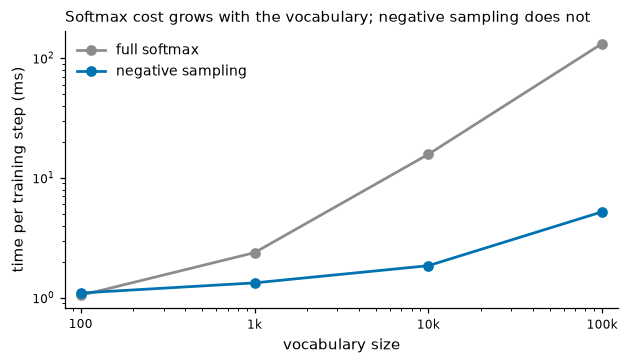

,softmax,negative
100,1.0,1.1
1000,2.4,1.3
10000,15.8,1.9
100000,132.3,5.2


In [13]:
E_soft, _, secs_soft = C.train_skipgram(train["tokens"], method="softmax", steps=1500)
quality = pd.DataFrame({"neighbours in the same class": [C.class_purity(E_soft), C.class_purity(E)],
                        "training time (s), vocabulary of 81": [secs_soft, secs_neg]}, index=["full softmax", "negative sampling (k=5)"])
display(quality.round(3))

def step_time(vocab, method, d=64, batch=1024, k=5, reps=5):
    m = C.SkipGram(vocab, d); opt = torch.optim.SGD(m.parameters(), 0.1)
    c, o = torch.randint(0, vocab, (batch,)), torch.randint(0, vocab, (batch,))
    t0 = time.time()
    for _ in range(reps):
        loss = m.loss_softmax(c, o) if method == "softmax" else m.loss_negative(c, o, torch.randint(0, vocab, (batch, k)))
        opt.zero_grad(); loss.backward(); opt.step()
    return 1000 * (time.time() - t0) / reps
vocabs = [100, 1000, 10000, 100000]
timing = pd.DataFrame({m: [step_time(v, m) for v in vocabs] for m in ["softmax", "negative"]}, index=vocabs)
fig, ax = plt.subplots(figsize=(5.6, 3.2))
ax.plot(vocabs, timing["softmax"], "o-", color=viz.GREY, label="full softmax")
ax.plot(vocabs, timing["negative"], "o-", color=viz.BLUE, label="negative sampling")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(vocabs); ax.set_xticklabels(["100", "1k", "10k", "100k"])
ax.set_xlabel("vocabulary size"); ax.set_ylabel("time per training step (ms)"); ax.legend()
ax.set_title("Softmax cost grows with the vocabulary; negative sampling does not")
plt.show()
display(timing.round(1))

**Reading the result.** On our 81-token vocabulary the two losses give embeddings of similar quality in similar
time, so the choice does not matter here. The timing panel shows why it mattered in practice. From 100 to 100,000
words the full-softmax step becomes roughly a hundred times slower, while negative sampling slows only a few-fold
(what remains is our simple optimiser touching the whole embedding table on every step). word2vec's contribution was
as much about cost as about quality.

## 9. What static embeddings cannot do

A skip-gram embedding gives each word **one vector, whatever sentence it appears in**. A common way to use such
vectors for a task is to average them over a document. We test that on the two hidden labels, with 200 labelled
documents for training.

,topic (which words),style (which order)
average of skip-gram embeddings,0.999,0.411
raw word counts,1.000,0.335


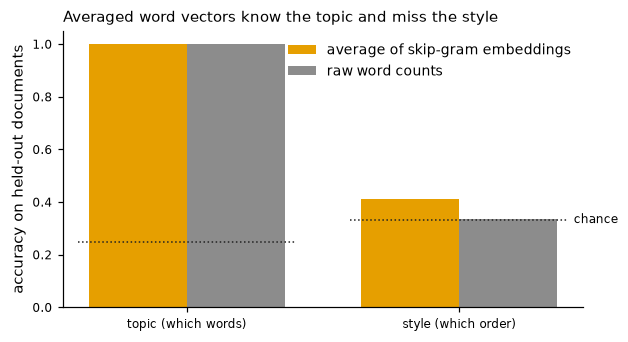

In [14]:
bag = lambda tok: E[tok].mean(1)
counts = lambda tok: np.stack([np.bincount(t, minlength=W.VOCAB) for t in tok]).astype(float)
probe = pd.DataFrame({"topic (which words)": [W.probe(bag, 200, "topic"), W.probe(counts, 200, "topic")],
                      "style (which order)": [W.probe(bag, 200, "style"), W.probe(counts, 200, "style")]},
                     index=["average of skip-gram embeddings", "raw word counts"])
display(probe.round(3))
fig, ax = plt.subplots(figsize=(5.6, 3))
x = np.arange(2)
ax.bar(x - 0.18, probe.iloc[0], 0.36, color=viz.ORANGE, label=probe.index[0])
ax.bar(x + 0.18, probe.iloc[1], 0.36, color=viz.GREY, label=probe.index[1])
ax.plot([-0.4, 0.4], [0.25, 0.25], color=viz.BLACK, ls=":", lw=1); ax.plot([0.6, 1.4], [1 / 3, 1 / 3], color=viz.BLACK, ls=":", lw=1)
ax.text(1.42, 1 / 3, "chance", fontsize=8, va="center")
ax.set_xticks(x); ax.set_xticklabels(probe.columns); ax.set_ylabel("accuracy on held-out documents"); ax.set_ylim(0, 1.05)
ax.set_title("Averaged word vectors know the topic and miss the style"); ax.legend(loc="upper right")
plt.show()

**Reading the result.** The topic, which is a matter of *which words* occur, is recovered almost perfectly. The style,
which is a matter of *word order*, is not: raw word counts are at chance (33%) and averaged embeddings reach only
about 41%. Averaging throws the order away, and each word's vector is the same in every context. To capture the style, a word's representation has to depend on
the words around it. That is the idea of **contextual** representations, and it is where notebook 02 goes.

## 10. Design choices: what changed since

| Choice | Original | What the field moved to | Why |
|---|---|---|---|
| Unseen events | add-k smoothing | Kneser–Ney back-off ([Chen & Goodman, 1996](https://arxiv.org/abs/cmp-lg/9606011)) | Uses shorter contexts when long ones are rare (ablated in section 4) |
| Generalising across contexts | separate count per context | learned embeddings | Similar words share statistics (section 6) |
| Training embeddings | full softmax | negative sampling, hierarchical softmax ([Mikolov et al., 2013](https://arxiv.org/abs/1310.4546)) | Cost independent of vocabulary size (ablated in section 8) |
| Source of the vectors | predict neighbours (skip-gram) | also factorise co-occurrence counts (GloVe, [Pennington et al., 2014](https://doi.org/10.3115/v1/D14-1162)) | Uses global counts directly; similar quality |
| Unit | one vector per whole word | vectors for character n-grams, summed (fastText, [Bojanowski et al., 2016](https://arxiv.org/abs/1607.04606)) | Handles rare and unseen words (Challenge Problem 2) |
| Context dependence | one vector per word | contextual vectors from a language model | Meaning depends on context (notebook 02) |

## 11. Scorecard

In [15]:
rows = [W.scorecard_row("unigram", results[("kn", 1)], params=W.VOCAB),
        W.scorecard_row(f"n-gram, Kneser-Ney, n={best_n}", results[("kn", best_n)]),
        W.scorecard_row("n-gram, Kneser-Ney, n=6", results[("kn", 6)]),
        W.scorecard_row("window neural LM, 4 tokens", mlp_res[4], params=sum(p.numel() for p in mlp[4].parameters()), train_seconds=mlp_secs[4]),
        W.scorecard_row("window neural LM, 16 tokens", mlp_res[16], params=sum(p.numel() for p in mlp[16].parameters()), train_seconds=mlp_secs[16]),
        dict(model="skip-gram embeddings, averaged", family="language", probe_style=probe.iloc[0, 1], probe_topic=probe.iloc[0, 0])]
metrics.append_rows(rows, "01_ngrams_embeddings")
display(metrics.load_scorecard()[["notebook", "model", "gap", "recall_d8", "recall_d32", "probe_style"]].round(3))

,notebook,model,gap,recall_d8,recall_d32,probe_style
0,01_ngrams_embeddings,unigram,1.714,0.000,0.000,NaN
1,01_ngrams_embeddings,"n-gram, Kneser-Ney, n=3",0.662,0.138,0.110,NaN
2,01_ngrams_embeddings,"n-gram, Kneser-Ney, n=6",0.835,0.128,0.138,NaN
3,01_ngrams_embeddings,"window neural LM, 4 tokens",0.483,0.150,0.130,NaN
4,01_ngrams_embeddings,"window neural LM, 16 tokens",0.269,1.000,0.144,NaN
5,01_ngrams_embeddings,"skip-gram embeddings, averaged",NaN,NaN,NaN,0.411


## Challenge Problem 1: How much data does counting need?

Train the Kneser–Ney models with $n = 3$ and $n = 5$, and the window neural model with 8 tokens of context, on the first 500, 2,000 and
20,000 training documents. Plot the gap to the floor against the number of documents. Which model is best with little data, which benefits most from more, and what does
that suggest about what would happen with a billion documents?

In [16]:
# Start your code here

### Challenge Problem 1 Solution

,"Kneser-Ney, n=3","Kneser-Ney, n=5","window neural LM, 8 tokens"
500,0.913,1.005,4.705
2000,0.782,0.923,0.961
20000,0.662,0.799,0.341


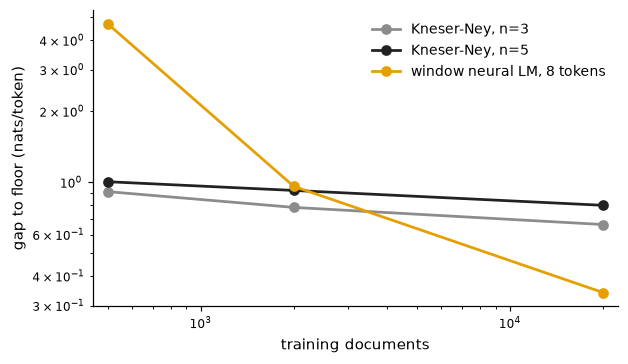

In [17]:
sizes = [500, 2000, 20000]
out = {"Kneser-Ney, n=3": [], "Kneser-Ney, n=5": [], "window neural LM, 8 tokens": []}
for s in sizes:
    sub = train["tokens"][:s]
    out["Kneser-Ney, n=3"].append(W.evaluate_lm(C.NGram(3, "kn").fit(sub).logprobs, distances=(8,))["gap"])
    out["Kneser-Ney, n=5"].append(W.evaluate_lm(C.NGram(5, "kn").fit(sub).logprobs, distances=(8,))["gap"])
    set_seed(0); m = C.WindowMLP(window=8); C.train_lm(m, sub, steps=1500, batch=min(64, s))
    out["window neural LM, 8 tokens"].append(W.evaluate_lm(m.logprobs, distances=(8,))["gap"])
df = pd.DataFrame(out, index=sizes); display(df.round(3))
fig, ax = plt.subplots(figsize=(5.6, 3.2))
for name, col in zip(df, [viz.GREY, viz.BLACK, viz.ORANGE]):
    ax.plot(sizes, df[name], "o-", color=col, label=name)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("training documents"); ax.set_ylabel("gap to floor (nats/token)"); ax.legend(); plt.show()
# Read the table before trusting a story. With 500 documents the neural model is by far the worst: 1,500 training
# steps on so little data memorise it (no early stopping or regularisation here), while smoothed counts degrade
# gracefully. With 20,000 documents the order reverses and the neural model is clearly best. Count models need
# every context to be seen many times, so the 5-gram never catches the 3-gram. Neural models share statistics
# between similar contexts, so they gain the most from more data, which is the regime pre-training lives in.

## Challenge Problem 2: Subword embeddings for words never seen in training

fastText ([Bojanowski et al., 2016](https://arxiv.org/abs/1607.04606)) represents a word as the sum of vectors for its character n-grams, so a word that never occurred in training
still gets a vector. Implement it for our language: give every word the character 2-grams and 3-grams of `<word>` (with `<` and `>` marking the
ends), train with the negative-sampling loss, and then build vectors for six **invented** words, one per suffix (for example `zzza`, `zzzek`).
For each invented word, report the classes of its five nearest real words. Why does this work in our language, and what property of real
languages does it rely on?

In [18]:
# Start your code here

### Challenge Problem 2 Solution

In [19]:
import torch.nn as nn
def grams(word):
    w = f"<{word}>"
    return [w[i:i + n] for n in (2, 3) for i in range(len(w) - n + 1)]
gram_ids = {}
for w in W.WORDS:
    for g in grams(w):
        gram_ids.setdefault(g, len(gram_ids))
def bag_of(words):
    idx = [[gram_ids[g] for g in grams(w) if g in gram_ids] for w in words]
    flat = torch.tensor([i for row in idx for i in row]); offsets = torch.tensor(np.cumsum([0] + [len(r) for r in idx[:-1]]))
    return flat, offsets
set_seed(0)
sub_in = nn.EmbeddingBag(len(gram_ids), 24, mode="sum"); out_emb = nn.Embedding(W.VOCAB, 24)
nn.init.normal_(sub_in.weight, std=0.05); nn.init.zeros_(out_emb.weight)
flat, offsets = bag_of(W.WORDS)
opt = torch.optim.Adam(list(sub_in.parameters()) + list(out_emb.parameters()), 0.01)
c, o = C.skipgram_pairs(train["tokens"])
freq = torch.as_tensor(np.bincount(train["tokens"].ravel(), minlength=W.VOCAB) ** 0.75, dtype=torch.float)
for step in range(1500):
    idx = torch.randint(0, len(c), (1024,))
    v = sub_in(flat, offsets)[c[idx]]                                        # word vector = sum of its n-gram vectors
    neg = torch.multinomial(freq, 1024 * 5, replacement=True).view(1024, 5)
    loss = -(torch.nn.functional.logsigmoid((v * out_emb(o[idx])).sum(-1)) +
             torch.nn.functional.logsigmoid(-(out_emb(neg) @ v[..., None])[..., 0]).sum(-1)).mean()
    opt.zero_grad(); loss.backward(); opt.step()
with torch.no_grad():
    E_sub = sub_in(flat, offsets).numpy()
    invented = ["zzz" + s for s in W.SUFFIX]
    E_new = sub_in(*bag_of(invented)).numpy()
real = E_sub[fill_ids] / np.linalg.norm(E_sub[fill_ids], axis=1, keepdims=True)
for word, vec in zip(invented, E_new):
    near = np.argsort(-(real @ (vec / np.linalg.norm(vec))))[:5]
    print(f"{word:6s} -> nearest real words: {[W.WORDS[fill_ids[i]] for i in near]}")
# The invented words land among real words with the same suffix, because the suffix n-grams carry the class.
# This relies on morphology: in real languages, parts of words (prefixes, suffixes, stems) carry meaning.
# Notebook 05 returns to this idea with byte-pair encoding, which is how modern models split words.

zzza   -> nearest real words: ['bala', 'peza', 'fuda', 'niza', 'gopa']
zzzek  -> nearest real words: ['demek', 'vorek', 'limek', 'titek', 'tobek']
zzzis  -> nearest real words: ['vazis', 'gebis', 'vasis', 'tadis', 'neris']
zzzom  -> nearest real words: ['sorom', 'dafom', 'vabom', 'vanom', 'lunom']
zzzur  -> nearest real words: ['lizur', 'potur', 'lilur', 'tovur', 'tulur']
zzzly  -> nearest real words: ['bizly', 'pivly', 'libly', 'panly', 'povly']


## Final summary

* A language model predicts the next token, and its quality has a hard lower bound. In our synthetic language that
  bound is known exactly, so every model in this series is scored by its **gap to the floor**.
* **Counting** works for short contexts and fails for long ones, because long contexts are almost never repeated.
  Smoothing (Kneser–Ney) limits the damage but does not remove it.
* **Embeddings** let a neural model share what it learns between similar contexts, so longer windows keep helping.
  Trained on their own (skip-gram), embeddings organise words by how they are used, and became the first reusable
  pretrained component.
* Two limits remain, and both were measured here. A **fixed window** cannot recall anything outside it, however the
  model is built. And **one vector per word** cannot represent anything that depends on word order. Notebook 02
  addresses both with networks that carry a state through the whole sequence.

## References

* C. E. Shannon (1948). **A Mathematical Theory of Communication**. *Bell System Technical Journal*. [doi.org/10.1002/j.1538-7305.1948.tb01338.x](https://doi.org/10.1002/j.1538-7305.1948.tb01338.x)
* C. E. Shannon (1951). **Prediction and Entropy of Printed English**. *Bell System Technical Journal*. [doi.org/10.1002/j.1538-7305.1951.tb01366.x](https://doi.org/10.1002/j.1538-7305.1951.tb01366.x)
* Stanley F. Chen, Joshua T. Goodman (1996). **An Empirical Study of Smoothing Techniques for Language Modeling**. arXiv:cmp-lg/9606011. [arxiv.org/abs/cmp-lg/9606011](https://arxiv.org/abs/cmp-lg/9606011)
* Tomas Mikolov, Kai Chen, Greg Corrado et al. (2013). **Efficient Estimation of Word Representations in Vector Space**. arXiv:1301.3781. [arxiv.org/abs/1301.3781](https://arxiv.org/abs/1301.3781)
* Tomas Mikolov, Ilya Sutskever, Kai Chen et al. (2013). **Distributed Representations of Words and Phrases and their Compositionality**. arXiv:1310.4546. [arxiv.org/abs/1310.4546](https://arxiv.org/abs/1310.4546)
* Jeffrey Pennington, Richard Socher, Christopher Manning (2014). **Glove: Global Vectors for Word Representation**. *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing (EMNLP)*. [doi.org/10.3115/v1/D14-1162](https://doi.org/10.3115/v1/D14-1162)
* Piotr Bojanowski, Edouard Grave, Armand Joulin et al. (2016). **Enriching Word Vectors with Subword Information**. arXiv:1607.04606. [arxiv.org/abs/1607.04606](https://arxiv.org/abs/1607.04606)
* Bengio, Ducharme, Vincent and Jauvin (2003). **A Neural Probabilistic Language Model**. *Journal of Machine Learning Research*. Not machine-verified: no arXiv ID, and the DOI record is empty, so no link is given.

The full, verified list for the series is in [`research_papers/README.md`](research_papers/README.md).